# Chapitre 12 - Exercices 12.6 à 12.10

Ce notebook traite les exercices 12.6 à 12.10, centrés sur la justesse de bout en
bout :

- **12.6** : identifiants de requête : relances, collisions et faux doublons (calcul et
  mini-lab) ;
- **12.7** : deux contraintes d'unicité à la fois, sans transaction (mini-lab) ;
- **12.8** : virement multi-partition : injecter une panne à chaque étape (mini-lab et
  calcul) ;
- **12.9** : combien de billets vendre en trop ? (calcul) ;
- **12.10** : comparer deux répliques avec un arbre de Merkle (calcul et mini-lab).

In [1]:
import math
import random
from math import comb

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import dataflow as dfl
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET, COLORS,
                           annotate_bars, finish, set_style, subtitle)

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
SHARD, SHARDS = "partition", "partitions"

## Exercice 12.6 : identifiants de requête : relances, collisions et faux doublons

**Énoncé.**

1. Un client renvoie sa requête tant qu'il ne reçoit pas de réponse, jusqu'à $m$ envois ;
   chaque réponse se perd indépendamment avec probabilité $p$ (la requête, elle, est
   toujours exécutée). Calculer le nombre moyen d'exécutions par requête sans
   déduplication. Application : $p = 0{,}1$, $m = 5$.
2. On identifie les requêtes par 64 bits aléatoires, à raison d'un milliard de requêtes
   par jour, conservés un an pour la déduplication. Quelle est la probabilité d'au moins
   une collision ? Et avec les 122 bits aléatoires d'un UUID v4 ?
3. Variante : l'identifiant est le hachage des champs du formulaire (compte source,
   bénéficiaire, montant, date). Chaque utilisateur fait 3 virements par jour vers l'un de
   ses 5 bénéficiaires habituels (au hasard), d'un montant pris parmi 10, 20, 50 et
   100 EUR (avec probabilités 0,4 ; 0,3 ; 0,2 ; 0,1). Quelle fraction des virements
   légitimes est supprimée à tort ? Simuler sur 100 000 utilisateurs.

**Rappels.** Une relance traverse TCP, la base et le 2PC ; seul un identifiant de bout en
bout la reconnaît (cours 4, sections 2 et 3 ; sections *Duplicate suppression* et
*Operation identifiers*).

**Solution.**

*1.* Le $i$-ième envoi a lieu si les $i - 1$ réponses précédentes se sont perdues :
$E = \sum_{i=1}^{m} p^{i-1} = \frac{1 - p^m}{1 - p}$. Pour $p = 0{,}1$, $m = 5$ :
$E = 0{,}99999/0{,}9 \approx 1{,}111$ : **11,1 %** d'exécutions en trop.

*2.* $n = 3{,}65 \cdot 10^{11}$ ; $n^2 / 2^{65} \approx 1{,}33 \cdot 10^{23} / 3{,}69 \cdot
10^{19} \approx 3\,600$, donc $P \approx 1 - e^{-3600} = 1$ : une collision est
**certaine** (sur une seule journée, déjà 2,7 %). Avec 122 bits :
$1{,}33 \cdot 10^{23} / 2^{123} \approx 1{,}3 \cdot 10^{-14}$, négligeable.

*3.* Pour un utilisateur, les 3 virements tombent dans des cases (bénéficiaire, montant) ;
un virement est supprimé à tort s'il tombe dans une case déjà occupée ce jour-là. Le
nombre attendu de cases distinctes est $\sum_c [1 - (1 - q_c)^3]$, où $q_c$ est la
probabilité de la case ; les virements supprimés sont $3 - E[\text{distinctes}]$. Avec
des montants uniformes (20 cases équiprobables), on trouverait $3 - 20(1 - 0{,}95^3)
\approx 0{,}15$ par utilisateur, soit 4,9 % ; avec des montants concentrés sur les petites
valeurs, c'est davantage (calcul ci-dessous).

**Vérification.**

In [2]:
p, m = 0.1, 5
E = (1 - p ** m) / (1 - p)
sim = dfl.retrying_client(dfl.make_bank_db({1: 0.0, 2: 1e7}), 20_000, p, use_ids=False, seed=2)
print(f"exécutions par requête : formule {E:.4f} ; simulation {sim['credited'] / sim['intended']:.4f}")
print(f"collision 64 bits sur un an : {dfl.uuid_collision_prob(3.65e11, 64):.6f} ; sur un jour : {dfl.uuid_collision_prob(1e9, 64):.4f} ; "
      f"122 bits sur un an : {dfl.uuid_collision_prob(3.65e11, 122):.1e}")
q_amount = np.array([0.4, 0.3, 0.2, 0.1])
q = np.outer(np.full(5, 0.2), q_amount).ravel()           # 20 cases (bénéficiaire, montant)
attendu = 3 - np.sum(1 - (1 - q) ** 3)
rng = np.random.default_rng(5)
n_users = 100_000
cases = rng.choice(20, size=(n_users, 3), p=q)
distinct = np.array([len(set(row)) for row in cases])
print(f"virements légitimes supprimés à tort : calcul {attendu / 3:.2%} ; simulation {(3 - distinct).sum() / (3 * n_users):.2%}")

exécutions par requête : formule 1.1111 ; simulation 1.1098
collision 64 bits sur un an : 1.000000 ; sur un jour : 0.0267 ; 122 bits sur un an : 1.3e-14
virements légitimes supprimés à tort : calcul 5.87% ; simulation 5.90%


Le hachage des champs supprime à tort **près de 6 %** des virements légitimes dans ce
scénario : beaucoup trop. Il faut un élément propre à chaque intention, par exemple un
jeton aléatoire généré à l'affichage du formulaire (et donc identique pour toutes les
relances de **ce** formulaire, mais différent pour le formulaire suivant).

> **À retenir.** Sans déduplication, un taux de réponses perdues $p$ coûte environ
> $p/(1-p)$ d'exécutions en trop. Un identifiant aléatoire doit être long (64 bits ne
> suffisent pas à l'échelle d'un an) ; un identifiant dérivé du contenu confond des
> intentions distinctes.

## Exercice 12.7 : deux contraintes d'unicité à la fois, sans transaction

**Énoncé.** À l'inscription, le **nom d'utilisateur** et l'**adresse e-mail** doivent être
uniques. Avec un journal partitionné, la demande devrait aller au partition du nom **et** à celui
de l'e-mail, qui sont en général différents.

1. Proposer un protocole en plusieurs étapes, sans transaction distribuée, qui garantit
   les deux unicités.
2. L'implémenter sur `dfl.Log` et le tester avec 3 000 demandes tirées dans de petits
   ensembles de noms et d'e-mails (beaucoup de conflits), traitées dans un ordre
   d'entrelacement aléatoire des partitions. Vérifier : aucune valeur attribuée deux fois,
   aucune réservation orpheline à la fin, chaque demande a un verdict.
3. Quel est l'inconvénient du protocole ? Le mesurer.

**Rappels.** Toutes les écritures susceptibles d'entrer en conflit passent par le même
partition ; une transaction multi-partition se découpe en étapes reliées par l'identifiant de
requête, avec compensation si nécessaire (cours 4, sections 5 et 6 ; cours 5, section 2).

**Solution.**

*1.* Réservation puis confirmation, avec compensation :

1. la demande `(id, nom, e-mail)` va au partition du **nom** ; si le nom est libre, il est
   **réservé** pour `id` et un message part vers le partition de l'**e-mail** ; sinon, refus ;
2. au partition de l'e-mail : s'il est libre, il est attribué à `id`, et un message
   « confirmer » repart vers le partition du nom ; sinon, refus et message « libérer » ;
3. au partition du nom : la réservation est confirmée ou libérée (transaction de
   compensation).

Chaque étape est traitée séquentiellement dans son partition : deux demandes pour le même nom
(ou le même e-mail) sont ordonnées par le journal. Les messages portent l'identifiant :
rejoués après une panne, ils seraient dédupliqués comme au cours 4.

*3.* Une réservation temporaire **bloque** le nom : une autre demande pour ce nom, arrivée
entre-temps, est refusée même si la première échoue ensuite sur l'e-mail. C'est un refus
« à tort », le prix d'une décision prise sans connaître l'issue (on pourrait faire
attendre la seconde demande au lieu de la refuser).

In [3]:
class Inscriptions:
    """Protocole réservation / confirmation / libération sur un journal partitionné."""
    def __init__(self, n_part, seed):
        self.log = dfl.Log(n_part)
        self.state = [dict() for _ in range(n_part)]      # clé ("u:nom" ou "e:mail") -> (id, statut)
        self.offset = [0] * n_part
        self.verdicts, self.refus_a_tort_possibles = {}, 0
        self.rng = random.Random(seed)
    def part(self, cle):
        return self.log.partition_of(cle)
    def soumettre(self, rid, nom, mail):
        self.log.append("u:" + nom, ("demande", rid, nom, mail), partition=self.part("u:" + nom))
    def traiter(self, p, evt):
        st = self.state[p]
        kind, rid, nom = evt[0], evt[1], evt[2]
        u = "u:" + nom
        if kind == "demande":
            mail = evt[3]
            if u in st:
                self.verdicts[rid] = "refusé (nom pris)"
                self.refus_a_tort_possibles += st[u][1] == "réservé"
            else:
                st[u] = (rid, "réservé")
                self.log.append("e:" + mail, ("email", rid, nom, mail), partition=self.part("e:" + mail))
        elif kind == "email":
            e = "e:" + evt[3]
            if e in st:
                self.verdicts[rid] = "refusé (e-mail pris)"
                self.log.append(u, ("libérer", rid, nom), partition=self.part(u))
            else:
                st[e] = (rid, "attribué")
                self.verdicts[rid] = "accepté"
                self.log.append(u, ("confirmer", rid, nom), partition=self.part(u))
        elif kind == "confirmer":
            st[u] = (rid, "confirmé")
        elif kind == "libérer" and st.get(u, (None,))[0] == rid:
            del st[u]
    def run(self):
        while True:
            pending = [p for p in range(self.log.n_partitions) if self.offset[p] < self.log.end_offset(p)]
            if not pending:
                return
            p = self.rng.choice(pending)
            _, _, evt = self.log.read(p, self.offset[p], 1)[0]
            self.traiter(p, evt)
            self.offset[p] += 1

rng = random.Random(7)
ins = Inscriptions(8, seed=1)
demandes = [(f"r{i}", f"nom{rng.randrange(800)}", f"mail{rng.randrange(800)}") for i in range(3000)]
for i, (rid, nom, mail) in enumerate(demandes):
    ins.soumettre(rid, nom, mail)
    if i % 100 == 99:
        ins.run()
ins.run()
cles = [(k, v) for st in ins.state for k, v in st.items()]
acceptes = {rid for rid, v in ins.verdicts.items() if v == "accepté"}
noms = [v[0] for k, v in cles if k.startswith("u:")]
mails = [v[0] for k, v in cles if k.startswith("e:")]
verif = {
    "demandes avec verdict": len(ins.verdicts),
    "acceptées": len(acceptes),
    "réservations orphelines (statut « réservé »)": sum(1 for k, v in cles if v[1] == "réservé"),
    "noms confirmés = acceptés ?": set(noms) == acceptes,
    "e-mails attribués = acceptés ?": set(mails) == acceptes,
    "refus à cause d'une réservation temporaire": ins.refus_a_tort_possibles,
}
pd.Series(verif, name="vérification").to_frame()

,vérification
demandes avec verdict,3000
acceptées,623
réservations orphelines (statut « réservé »),0
noms confirmés = acceptés ?,True
e-mails attribués = acceptés ?,True
refus à cause d'une réservation temporaire,81


Les 3 000 demandes ont un verdict ; chaque nom et chaque e-mail appartient à au plus une
demande acceptée (ce sont des clés de dictionnaire, et les ensembles coïncident avec les
acceptées) ; aucune réservation ne reste en suspens. Le protocole a toutefois refusé
quelques demandes parce que le nom était **temporairement** réservé par une demande
encore en cours, dont certaines ont ensuite échoué sur l'e-mail : c'est l'inconvénient
annoncé.

> **À retenir.** Plusieurs contraintes d'unicité sur des clés différentes se traitent par
> étapes : réserver, vérifier ailleurs, confirmer ou compenser. On garde l'unicité sans
> transaction distribuée, au prix d'états intermédiaires visibles (refus à tort ou
> attentes).

## Exercice 12.8 : virement multi-partition : injecter une panne à chaque étape

**Énoncé.** On reprend `dfl.PaymentSystem` (cours 4, section 6) avec un seul virement de
30 EUR d'Alice (100 EUR) vers Bob (20 EUR), avec 1 EUR de frais.

1. Lister les événements traités sans panne et les soldes finaux attendus.
2. Pour **chaque** étape de traitement et **chaque** point de panne possible (après $k$
   sorties émises, $k = 0, 1, \dots$), rejouer le scénario et vérifier que les soldes
   finaux sont corrects.
3. Comparer le nombre d'écritures et d'attentes synchrones avec une validation en deux
   phases (2PC) sur les trois partitions concernés. En supposant qu'une transaction 2PC
   garde ses verrous pendant deux allers-retours de 1 ms, quel débit maximal peut
   atteindre un compte très sollicité (un marchand populaire) ? Et avec le traitement par
   journal, si un processeur traite 50 000 événements/s ?

**Rappels.** Atomicité par l'ajout unique au journal, processeurs déterministes,
livraison au moins une fois, déduplication par identifiant (cours 4, section 6 ; section
*Multi-partition request processing*).

**Solution.** *1.* Quatre événements : la demande (journal d'Alice), le débit de 31 EUR
(journal d'Alice), le crédit de 30 EUR (journal de Bob), le crédit de 1 EUR (journal des
frais). Soldes attendus : Alice 69, Bob 50, frais 1.

*2.* Voir le code : on remplace le générateur aléatoire par un objet qui force **une**
panne à l'étape choisie, après $k$ sorties.

In [4]:
class PanneForcee:
    """Imite random.Random : provoque une panne (une seule fois), après k sorties émises."""
    def __init__(self, k):
        self.k, self.used = k, False
    def random(self):
        if self.used:
            return 1.0
        self.used = True
        return 0.0
    def randrange(self, n):
        return min(self.k, n - 1)

def scenario(etape_panne=None, k=0):
    ps = dfl.PaymentSystem({"alice": 100.0, "bob": 20.0}, n_shards=3, fee=1.0)
    ps.submit("r1", "alice", "bob", 30.0)
    s, trace = 0, []
    while True:
        pending = [q for q in range(3) if ps.procs[q].offset < ps.log.end_offset(q)]
        if not pending:
            return ps, trace
        q = pending[0]
        _, _, evt = ps.log.read(q, ps.procs[q].offset, 1)[0]
        if s == etape_panne:
            ps.step(q, PanneForcee(k), p_crash=1.0)
            trace.append(f"PANNE pendant {evt[0]} ({k} sortie(s) émise(s))")
        else:
            ps.step(q)
            trace.append(f"{evt[0]} {evt[2]} {evt[3] if len(evt) > 3 else ''}")
        s += 1

ref, trace = scenario()
print("sans panne :", trace, "→", ref.balances())
rows = []
for etape in range(4):
    for k in range(5):
        ps, tr = scenario(etape, k)
        b = ps.balances()
        rows.append({"étape en panne": etape, "sorties émises avant la panne": k,
                     "soldes corrects": b == ref.balances(), "événements écrits": len(ps.log),
                     "statuts reçus": len(ps.status["r1"])})
R = pd.DataFrame(rows).drop_duplicates(subset=["étape en panne", "événements écrits", "statuts reçus"])
print("scénarios testés :", len(rows), "; tous corrects :", all(r["soldes corrects"] for r in rows))
R

sans panne : ['demande alice bob', 'crédit bob 30.0', 'débit alice 31.0', 'crédit frais 1.0'] → {'bob': 50.0, 'alice': 69.0, 'frais': 1.0}
scénarios testés : 20 ; tous corrects : True


,étape en panne,sorties émises avant la panne,soldes corrects,événements écrits,statuts reçus
0,0,0,True,4,1
1,0,1,True,5,1
2,0,2,True,6,1
3,0,3,True,7,1
4,0,4,True,7,2
5,1,0,True,4,1
10,2,0,True,4,1
15,3,0,True,4,1


Les vingt scénarios (quatre étapes, cinq points de panne, dont certains équivalents)
finissent avec les bons soldes. Une panne pendant la demande, après $k$ sorties, produit
jusqu'à trois événements en double et un statut en double ; tous sont absorbés par la
déduplication. Une panne pendant un débit ou un crédit (qui n'émettent rien) ne fait que
retarder l'application.

*3.* **2PC** sur trois participants : une préparation et un vote par participant, puis une
décision et un acquittement par participant, soit **12 messages**, une écriture durable
du coordinateur et trois de chaque participant (préparé, puis validé), et surtout des
**verrous** tenus pendant environ deux allers-retours. Un compte très sollicité ne peut
alors voir passer qu'une transaction à la fois : au plus $1 / 2\ \text{ms} = $ **500
virements/s**. **Journal** : un ajout initial, puis trois événements émis (plus le
statut), soit 5 ajouts, sans attente synchrone ni verrou entre partitions ; le compte du marchand
n'est limité que par son processeur, soit environ **50 000 événements/s**, cent fois plus.

In [5]:
rtt = 1e-3
cmp_ = pd.DataFrame({
    "approche": ["validation en deux phases", "journal + identifiant de requête"],
    "messages ou ajouts par virement": [12, 5],
    "attente synchrone entre " + SHARDS: ["oui (2 allers-retours, verrous)", "non"],
    "débit max sur un compte chaud (/s)": [1 / (2 * rtt), 50_000]})
cmp_

,approche,messages ou ajouts par virement,attente synchrone entre partitions,débit max sur un compte chaud (/s)
0,validation en deux phases,12,"oui (2 allers-retours, verrous)",500.0
1,journal + identifiant de requête,5,non,50000.0


> **À retenir.** Injecter une panne à chaque point possible est la meilleure façon de se
> convaincre d'un protocole : ici, des processeurs déterministes et la déduplication par
> identifiant rendent toutes les pannes inoffensives. Sans verrous entre partitions, un compte
> chaud n'est plus limité par la latence de la coordination.

## Exercice 12.9 : combien de billets vendre en trop ?

**Énoncé.** Un avion a $C = 180$ places. Chaque acheteur se présente indépendamment avec
probabilité $p = 0{,}92$. Un billet rapporte 150 EUR (non remboursé en cas d'absence) ; un
passager refoulé coûte une indemnité de 600 EUR. On vend $n \ge C$ billets.

1. Exprimer le nombre moyen de refoulés $E[(X - C)^+]$, avec $X \sim \mathcal{B}(n, p)$.
2. Montrer que vendre le billet $n+1$ augmente le nombre moyen de refoulés de
   $p \cdot P(X_n \ge C)$, où $X_n \sim \mathcal{B}(n, p)$. En déduire la règle : vendre
   tant que $600 \cdot p \cdot P(X_n \ge C) < 150$.
3. Trouver le $n$ optimal et la probabilité de refouler au moins un passager.
4. Quel lien avec les contraintes « interprétées souplement » du livre ?

**Rappels.** On peut écrire d'abord et vérifier ensuite quand le coût de l'excuse est
acceptable (cours 5, section 2 ; section *Loosely interpreted constraints*).

**Solution.**

*1.* $E[(X-C)^+] = \sum_{k > C} (k - C)\binom{n}{k}p^k(1-p)^{n-k}$.

*2.* Écrivons $X_{n+1} = X_n + Y$ avec $Y \sim$ Bernoulli($p$) indépendant. Le nombre de
refoulés augmente de 1 exactement quand le nouveau passager vient ($Y = 1$) et que l'avion
était déjà plein ou plus ($X_n \ge C$) : l'accroissement moyen vaut $p\,P(X_n \ge C)$. Le
billet supplémentaire rapporte 150 EUR et coûte en moyenne $600\,p\,P(X_n \ge C)$ : on le
vend si ce coût est inférieur à 150.

*3.* Voir le calcul : $600 \times 0{,}92 \times P(X_{192} \ge 180) \approx 126 < 150$, mais
$600 \times 0{,}92 \times P(X_{193} \ge 180) \approx 173 > 150$ : on vend le 193e billet et
pas le 194e, soit **13 billets en trop**, avec environ 22 % de risque de refouler quelqu'un.

*4.* « Un siège par passager » est une contrainte d'unicité que la compagnie viole
**délibérément** : elle accepte des violations temporaires, réparées par une
compensation (l'indemnité), parce que le coût moyen des excuses est inférieur au gain. La
vérification a lieu à l'embarquement, pas à la vente.

optimum par recherche exhaustive : 193 billets


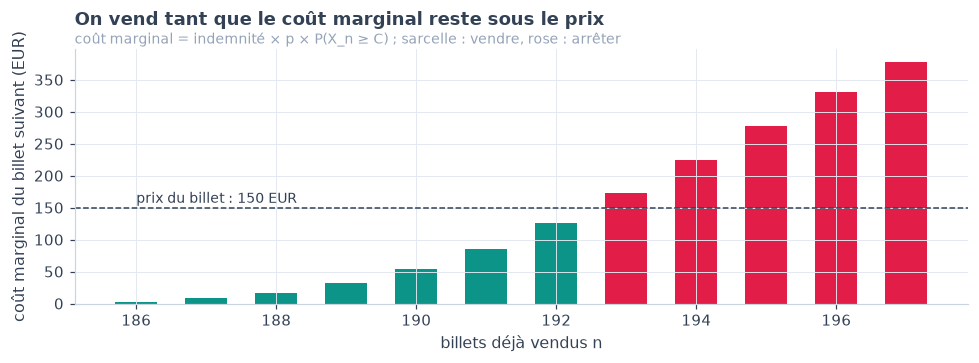

,billets vendus n,coût marginal du billet n+1 (EUR),vendre le n+1 ?,P(au moins un refoulé),recette espérée (EUR)
0,186,3.5786,True,0.0023,27898.1304
1,187,8.3641,True,0.0061,28044.5517
2,188,17.3129,True,0.0144,28186.1877
3,189,32.2673,True,0.0300,28318.8748
4,190,54.8785,True,0.0562,28436.6075
5,191,86.1229,True,0.0960,28531.7290
6,192,125.9075,True,0.1512,28595.6061
7,193,172.9146,False,0.2219,28619.6986
8,194,224.7566,False,0.3059,28596.7840
9,195,278.3959,False,0.3991,28522.0273


In [6]:
C, p, prix, ind = 180, 0.92, 150.0, 600.0
rows = []
for n in range(186, 198):
    pge = sum(comb(n, k) * p ** k * (1 - p) ** (n - k) for k in range(C, n + 1))
    p_bump = sum(comb(n, k) * p ** k * (1 - p) ** (n - k) for k in range(C + 1, n + 1))
    rows.append({"billets vendus n": n, "coût marginal du billet n+1 (EUR)": ind * p * pge,
                 "vendre le n+1 ?": ind * p * pge < prix, "P(au moins un refoulé)": p_bump,
                 "recette espérée (EUR)": dfl.overbooking_profit(n, C, p, prix, ind)})
R = pd.DataFrame(rows)
best, _ = dfl.best_overbooking(C, p, prix, ind)
print("optimum par recherche exhaustive :", C + best, "billets")
fig, ax = plt.subplots(figsize=(9, 3.4))
ax.bar(R["billets vendus n"], R["coût marginal du billet n+1 (EUR)"], color=[TEAL if v else ROSE for v in R["vendre le n+1 ?"]], width=0.6)
ax.axhline(prix, color=SLATE, ls="--", lw=1); ax.text(186, prix + 8, "prix du billet : 150 EUR", fontsize=9, color=SLATE)
ax.set_xlabel("billets déjà vendus n"); ax.set_ylabel("coût marginal du billet suivant (EUR)")
ax.set_title("On vend tant que le coût marginal reste sous le prix")
subtitle(ax, "coût marginal = indemnité × p × P(X_n ≥ C) ; sarcelle : vendre, rose : arrêter")
plt.tight_layout(); plt.show()
R

Le raisonnement marginal retrouve l'optimum de la recherche exhaustive (193 billets).

> **À retenir.** Une contrainte souple se règle par un calcul économique : on accepte des
> violations dont l'excuse coûte moins que ce que rapporte la souplesse. Le raisonnement
> marginal ($p \cdot P(X_n \ge C) \cdot$ indemnité contre prix) donne directement l'optimum.

## Exercice 12.10 : comparer deux répliques avec un arbre de Merkle

**Énoncé.** Deux répliques contiennent chacune $n = 2^{20}$ enregistrements (environ un
million), dont $k$ diffèrent (corruption silencieuse ou écritures perdues). On veut
trouver les enregistrements qui diffèrent en échangeant le moins de données possible.

1. Combien d'octets faut-il échanger pour comparer tous les hachages (32 octets chacun) ?
2. Avec un arbre de Merkle, on compare les racines puis on ne descend que dans les
   sous-arbres différents. Majorer le nombre de comparaisons de hachages par
   $2k\,(\log_2(n/k) + 1)$ (environ) et l'évaluer pour $k = 1, 10, 1000$.
3. Vérifier avec `dfl.MerkleTree.diff` sur $n = 2^{16}$ pour plusieurs valeurs de $k$.
4. Taille d'une preuve d'inclusion dans un journal de transparence d'un milliard
   d'entrées ?

**Rappels.** Arbres de Merkle, preuves d'inclusion en $\log_2 n$, anti-entropie (cours 5,
section 6 ; section *Tools for auditable data systems*).

**Solution.**

*1.* $2^{20} \times 32$ octets = **32 Mio** (et autant de comparaisons).

*2.* Les $k$ chemins racine-feuille partagent leurs premiers niveaux. Jusqu'à la
profondeur $\log_2 k$, l'arbre a au plus $k$ nœuds par niveau, en tout moins de $2k$
nœuds ; au-delà, chaque feuille différente a son propre chemin de $\log_2(n/k)$ nœuds, dont
on compare les deux enfants. Total : environ $2k\,(\log_2(n/k) + 1)$ comparaisons. Pour
$n = 2^{20}$ : $k = 1$ donne 42 ; $k = 10$, environ 286 ; $k = 1000$, environ 22 000, soit
0,7 Mio de hachages au lieu de 32 Mio.

*4.* $\lceil \log_2 10^9 \rceil = 30$ hachages, soit **960 octets** : une preuve tient dans
un paquet réseau, quel que soit le volume du journal.

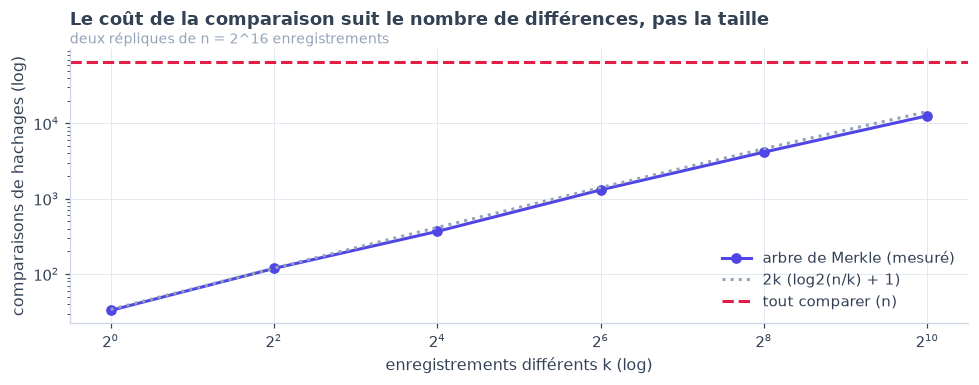

preuve d'inclusion pour 1e9 entrées : 30 hachages = 960 octets


,k (différences),trouvées,comparaisons,majorant 2k(log2(n/k)+1),tout comparer
0,1,1,33,34.0,65536
1,4,4,119,120.0,65536
2,16,16,369,416.0,65536
3,64,64,1311,1408.0,65536
4,256,256,4157,4608.0,65536
5,1024,1024,12605,14336.0,65536


In [7]:
n_bits = 16
n = 2 ** n_bits
base = [f"enr-{i}" for i in range(n)]
ta = dfl.MerkleTree(base)
rows = []
rng = random.Random(3)
for k in [1, 4, 16, 64, 256, 1024]:
    other = list(base)
    for i in rng.sample(range(n), k):
        other[i] = "corrompu"
    diff, comps = ta.diff(dfl.MerkleTree(other))
    rows.append({"k (différences)": k, "trouvées": len(diff), "comparaisons": comps,
                 "majorant 2k(log2(n/k)+1)": 2 * k * (math.log2(n / k) + 1), "tout comparer": n})
R = pd.DataFrame(rows)
fig, ax = plt.subplots(figsize=(9, 3.6))
ax.plot(R["k (différences)"], R["comparaisons"], "o-", color=INDIGO, label="arbre de Merkle (mesuré)")
ax.plot(R["k (différences)"], R["majorant 2k(log2(n/k)+1)"], color=GRAY, ls=":", label="2k (log2(n/k) + 1)")
ax.axhline(n, color=ROSE, ls="--", label="tout comparer (n)")
ax.set_xscale("log", base=2); ax.set_yscale("log")
ax.set_xlabel("enregistrements différents k (log)"); ax.set_ylabel("comparaisons de hachages (log)")
ax.set_title("Le coût de la comparaison suit le nombre de différences, pas la taille")
subtitle(ax, f"deux répliques de n = 2^{n_bits} enregistrements")
ax.legend(); plt.tight_layout(); plt.show()
print("preuve d'inclusion pour 1e9 entrées :", math.ceil(math.log2(1e9)), "hachages =", math.ceil(math.log2(1e9)) * 32, "octets")
R

Toutes les différences sont retrouvées, et le nombre de comparaisons reste sous le
majorant (il s'en approche quand les différences sont dispersées). Pour une poignée de
différences, quelques dizaines de comparaisons suffisent au lieu de 65 536 ; l'avantage
s'amenuise quand une grande fraction des enregistrements diffère (il vaut alors mieux
tout renvoyer).

> **À retenir.** Un arbre de Merkle localise $k$ différences parmi $n$ enregistrements en
> $O(k \log(n/k))$ comparaisons et prouve l'appartenance d'un enregistrement en
> $\log_2 n$ hachages : de quoi auditer et réparer des répliques sans tout transférer.